# TRSP Thesis Figures
Generates the figures for section 6.5.3 (Testing Results) of the thesis.
Outputs saved to `results/figures/`.

| Figure | File | Description |
|--------|------|-------------|
| 1 | `psl_agent_comparison.png` | PSL agents × networks, mean over K=1–4 |
| 2 | `effect_of_k.png` | K-effect on makespan + success, mean over networks |
| 3 | `svc_agent_comparison.png` | SVC agents × networks |
| 4 | `ped_agent_comparison.png` | Ped agents × networks — Dijkstra vs DQN, common successful OD pairs |
| 5 | `highlight_routes_dqn_vs_dijkstra.png` | Best DQN wins over Dijkstra — PSL vs SVC × networks |

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# serif fonts to match LaTeX output
plt.rcParams.update({
    'font.size': 11,
    'font.family': 'serif',
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'legend.fontsize': 9,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
})

BASE = Path('..').resolve()
RUNS = BASE / 'runs' / 'trsp'
FIG_DIR = BASE / 'results' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
print('Base:', BASE)
print('Figures will be saved to:', FIG_DIR)

Base: /home/shinobi-owl/PhD/battery/DroneSim
Figures will be saved to: /home/shinobi-owl/PhD/battery/DroneSim/results/figures


## Constants

In [2]:
NET_ORDER = ['Grid', 'Rand-Grid', 'Ames']

PSL_ALGO_ORDER  = ['SSP', 'SARSA', 'DQN', 'PPO', 'A2C']
PSL_ALGO_COLORS = ['#4c72b0', '#dd8452', '#55a868', '#c44e52', '#8172b3']

SVC_ALGO_ORDER  = ['SSP', 'DSP', 'SARSA', 'DQN', 'A2C', 'PPO']
SVC_ALGO_COLORS = ['#4c72b0', '#937860', '#dd8452', '#55a868', '#8172b3', '#c44e52']

# line styles for K-effect plot
K_STYLES = {
    'SSP':   ('-',  'o', '#4c72b0'),
    'SARSA': ('-',  's', '#dd8452'),
    'DQN':   ('-',  '^', '#55a868'),
    'PPO':   ('--', 'D', '#c44e52'),
    'A2C':   ('--', 'v', '#8172b3'),
}

## Load Data

In [3]:
df_raw = pd.read_csv(BASE / 'results' / 'trsp_results.csv')

net_map = {'N1': 'Grid', 'N2': 'Rand-Grid', 'N3': 'Ames'}

# PSL rows (traffic T1–T4; excludes the separate 'TD' traffic scenario)
df_psl = df_raw[df_raw['traffic'].str.match(r'^T[1-4]$')].copy()
df_psl['network']     = df_psl['network'].map(net_map)
df_psl['K']           = df_psl['traffic'].str[1].astype(int)
df_psl['agent']       = df_psl['algo'].map({'dijkstra': 'SSP', 'sarsa': 'SARSA',
                                             'dqn': 'DQN', 'ppo': 'PPO', 'a2c': 'A2C'})
df_psl['success_pct'] = df_psl['success_rate'] * 100

# SVC rows (single seeded scenario 'SVC-svc_42'; excludes a stray unseeded 'SVC-svc' duplicate)
df_svc = df_raw[df_raw['traffic'] == 'SVC-svc_42'].copy()
df_svc['network']     = df_svc['network'].map(net_map)
df_svc['agent']       = df_svc['algo'].map({'dijkstra': 'SSP', 'dsp': 'DSP',
                                             'sarsa_svc': 'SARSA', 'dqn_svc': 'DQN',
                                             'a2c_svc': 'A2C', 'ppo_svc': 'PPO'})
df_svc['success_pct'] = df_svc['success_rate'] * 100

print(f'PSL rows: {len(df_psl)}  |  SVC rows: {len(df_svc)}')
print('PSL agents:', df_psl['agent'].dropna().unique().tolist())
print('SVC agents:', df_svc['agent'].dropna().unique().tolist())

PSL rows: 60  |  SVC rows: 18
PSL agents: ['DQN', 'PPO', 'A2C', 'SSP', 'SARSA']
SVC agents: ['DQN', 'A2C', 'PPO', 'SARSA', 'SSP', 'DSP']


## Figure 1 — PSL Agent Comparison (mean over K=1–4)

Saved: /home/shinobi-owl/PhD/battery/DroneSim/results/figures/psl_agent_comparison.png


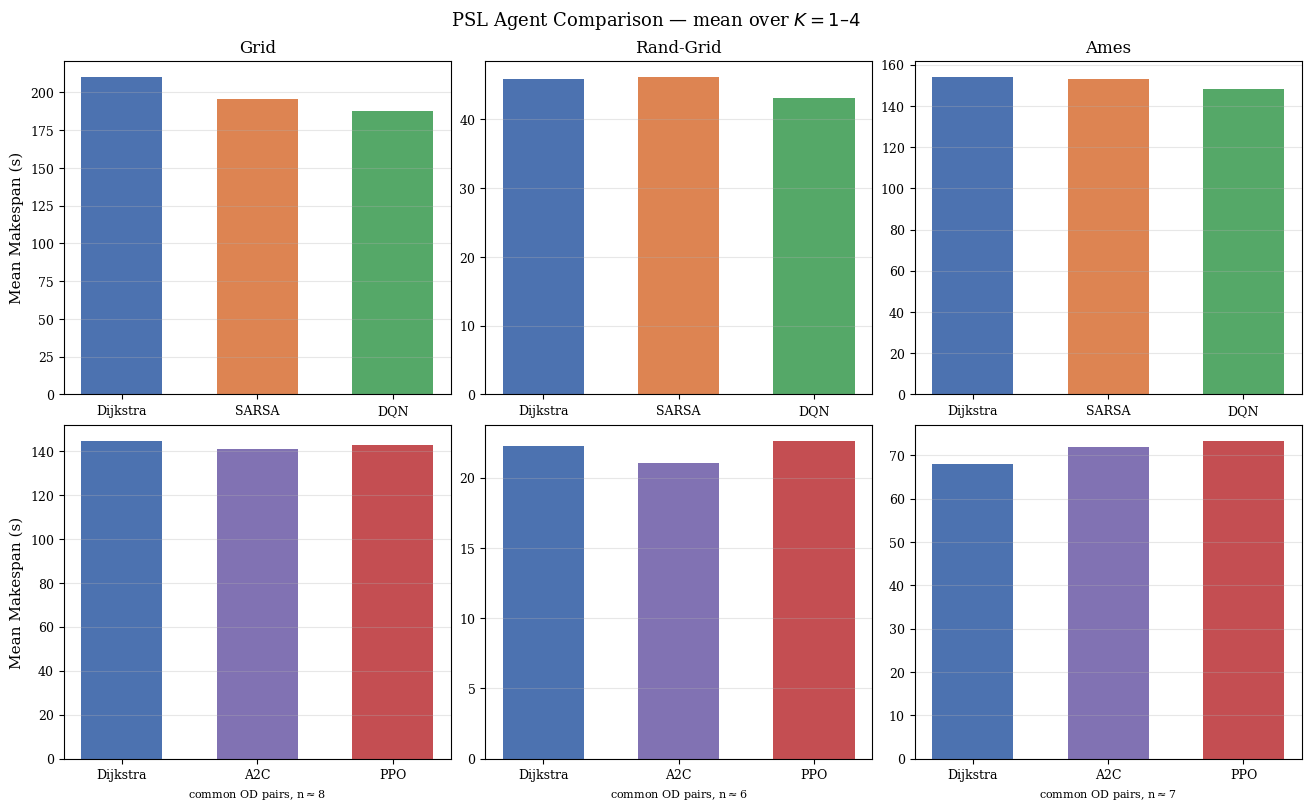

In [4]:
import yaml

NET_CODE = {v: k for k, v in net_map.items()}
NET_PATH = {
    'Grid':      'data/grid_road/grid_road.sumocfg',
    'Rand-Grid': 'data/rand_grid_road/rand_grid_road_final.sumocfg',
    'Ames':      'data/ames/ames_campus_final.sumocfg',
}

def _is_success(df):
    """A row counts as successful only if it finished AND its time is physically
    plausible for its path length.

    Some rows (mostly *_svc.csv reactive replays) log a near-zero total_time_taken
    for a real multi-edge path -- a logging artifact, not a fast route (verified:
    no legitimate row anywhere in runs/trsp/ travels faster than ~2s/edge, and the
    corpus-wide time/edge distribution has a clean gap between ~0.25 and ~5s/edge).
    Floor total_time_taken at 2s/edge to exclude these.
    """
    s = df['failed_error'].astype('string').str.strip().str.lower()
    finished   = (df['failed_error'].isna() | s.isin(['', 'na', 'nan', 'none'])) & (df['total_time_taken'] > 0)
    plausible  = df['total_time_taken'] >= 2.0 * df['path_length'].clip(lower=1)
    return finished & plausible

def _od_times(csv_path):
    """(start_idx, target_idx) -> total_time_taken for successful runs.

    The eval sampler draws OD pairs with replacement, so the same pair can recur
    within one run; any (start, target) pair that recurs is dropped entirely
    rather than guessing which occurrence to trust.
    """
    df = pd.read_csv(csv_path)
    df['start_idx']        = pd.to_numeric(df['start_idx'], errors='coerce')
    df['target_idx']       = pd.to_numeric(df['target_idx'], errors='coerce')
    df['total_time_taken'] = pd.to_numeric(df['total_time_taken'], errors='coerce')
    d = df[_is_success(df)].drop_duplicates(subset=['start_idx', 'target_idx'], keep=False)
    return d.set_index(['start_idx', 'target_idx'])['total_time_taken']

_dij_csv_cache = {}
def _dijkstra_csv(net_disp, K):
    if (net_disp, K) not in _dij_csv_cache:
        for test_dir in sorted((RUNS / 'dijkstra').glob('test_*'), key=lambda p: int(p.name.split('_')[1])):
            cfg_path = test_dir / 'config.yaml'
            if not cfg_path.exists():
                continue
            cfg  = yaml.safe_load(cfg_path.read_text())
            traf = cfg.get('traffic', {})
            if (cfg.get('net', {}).get('net_path') == NET_PATH[net_disp]
                    and traf.get('K') == K and traf.get('model') is None):
                _dij_csv_cache[(net_disp, K)] = test_dir / 'simulation_results.csv'
                break
    return _dij_csv_cache[(net_disp, K)]

def _agent_csv(net_code, K, algo):
    row = df_raw[(df_raw['network'] == net_code) & (df_raw['traffic'] == f'T{K}') & (df_raw['algo'] == algo)].iloc[0]
    test_dir = sorted((RUNS / row['model']).glob('test_*'))[0]
    return test_dir / 'simulation_results.csv'

TOP_ALGO_ORDER  = ['SSP', 'SARSA', 'DQN']
TOP_ALGO_LABELS = ['Dijkstra', 'SARSA', 'DQN']
TOP_ALGO_COLORS = [PSL_ALGO_COLORS[PSL_ALGO_ORDER.index(a)] for a in TOP_ALGO_ORDER]

BOTTOM_ALGO_ORDER  = ['Dijkstra', 'A2C', 'PPO']
BOTTOM_ALGO_COLORS = [PSL_ALGO_COLORS[PSL_ALGO_ORDER.index(a)] for a in ['SSP', 'A2C', 'PPO']]

# top row: each agent's own successful-OD mean makespan (unchanged), mean over K = 1-4
psl_avg = df_psl.groupby(['network', 'agent'])[['makespan_mean']].mean().reset_index()

# bottom row: per network & K, intersect the OD pairs Dijkstra/A2C/PPO all solved
# successfully, average each agent's makespan over that common subset, then mean
# the per-K results over K = 1-4
bottom_rows, bottom_ncommon = [], {}
for net_disp in NET_ORDER:
    net_code = NET_CODE[net_disp]
    per_k = {a: [] for a in BOTTOM_ALGO_ORDER}
    n_common = []
    for K in (1, 2, 3, 4):
        times = {
            'Dijkstra': _od_times(_dijkstra_csv(net_disp, K)),
            'A2C':      _od_times(_agent_csv(net_code, K, 'a2c')),
            'PPO':      _od_times(_agent_csv(net_code, K, 'ppo')),
        }
        common = list(set(times['Dijkstra'].index) & set(times['A2C'].index) & set(times['PPO'].index))
        n_common.append(len(common))
        for a in BOTTOM_ALGO_ORDER:
            per_k[a].append(times[a].loc[common].mean())
    bottom_ncommon[net_disp] = np.mean(n_common)
    for a in BOTTOM_ALGO_ORDER:
        bottom_rows.append({'network': net_disp, 'agent': a, 'makespan_mean': np.mean(per_k[a])})
bottom_avg = pd.DataFrame(bottom_rows)

# --- plot ---
x     = np.arange(3)
width = 0.6

fig, axes = plt.subplots(2, 3, figsize=(13, 8), constrained_layout=True)
fig.suptitle('PSL Agent Comparison — mean over $K = 1$–$4$', fontsize=13)

for col, net in enumerate(NET_ORDER):
    sub = psl_avg[psl_avg['network'] == net].set_index('agent')
    ax = axes[0, col]
    vals = [sub.loc[a, 'makespan_mean'] if a in sub.index else np.nan for a in TOP_ALGO_ORDER]
    ax.bar(x, vals, width, color=TOP_ALGO_COLORS)
    ax.set_title(net, fontsize=12)
    ax.set_xticks(x); ax.set_xticklabels(TOP_ALGO_LABELS)
    if col == 0: ax.set_ylabel('Mean Makespan (s)')
    ax.grid(True, axis='y', alpha=0.3)

    sub_b = bottom_avg[bottom_avg['network'] == net].set_index('agent')
    ax = axes[1, col]
    vals = [sub_b.loc[a, 'makespan_mean'] if a in sub_b.index else np.nan for a in BOTTOM_ALGO_ORDER]
    ax.bar(x, vals, width, color=BOTTOM_ALGO_COLORS)
    ax.set_xticks(x); ax.set_xticklabels(BOTTOM_ALGO_ORDER)
    ax.set_xlabel(f'common OD pairs, n$\\approx${bottom_ncommon[net]:.0f}', fontsize=8)
    if col == 0: ax.set_ylabel('Mean Makespan (s)')
    ax.grid(True, axis='y', alpha=0.3)

out = FIG_DIR / 'psl_agent_comparison.png'
fig.savefig(out, bbox_inches='tight', dpi=150)
print('Saved:', out)
plt.show()

## Figure 2 — Effect of K (mean over all networks)

Saved: /home/shinobi-owl/PhD/battery/DroneSim/results/figures/effect_of_k.png


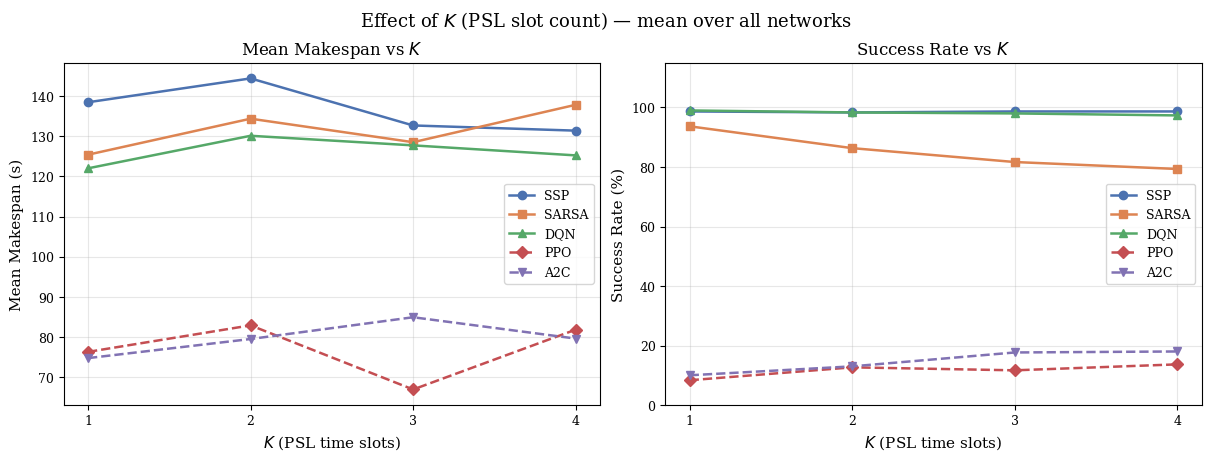

In [5]:
k_avg = df_psl.groupby(['K', 'agent'])[['makespan_mean', 'success_pct']].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
fig.suptitle('Effect of $K$ (PSL slot count) — mean over all networks', fontsize=13)

for algo in PSL_ALGO_ORDER:
    ls, marker, color = K_STYLES[algo]
    sub = k_avg[k_avg['agent'] == algo].sort_values('K')
    axes[0].plot(sub['K'], sub['makespan_mean'], linestyle=ls, marker=marker,
                 color=color, label=algo, linewidth=1.8, markersize=6)
    axes[1].plot(sub['K'], sub['success_pct'],   linestyle=ls, marker=marker,
                 color=color, label=algo, linewidth=1.8, markersize=6)

for ax, ylabel, title in zip(axes,
        ['Mean Makespan (s)', 'Success Rate (%)'],
        ['Mean Makespan vs $K$', 'Success Rate vs $K$']):
    ax.set_xlabel('$K$ (PSL time slots)')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_xticks([1, 2, 3, 4])
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
axes[1].set_ylim(0, 115)

out = FIG_DIR / 'effect_of_k.png'
fig.savefig(out, bbox_inches='tight', dpi=150)
print('Saved:', out)
plt.show()

## Figure 3 — SVC Agent Comparison

Saved: /home/shinobi-owl/PhD/battery/DroneSim/results/figures/svc_agent_comparison.png


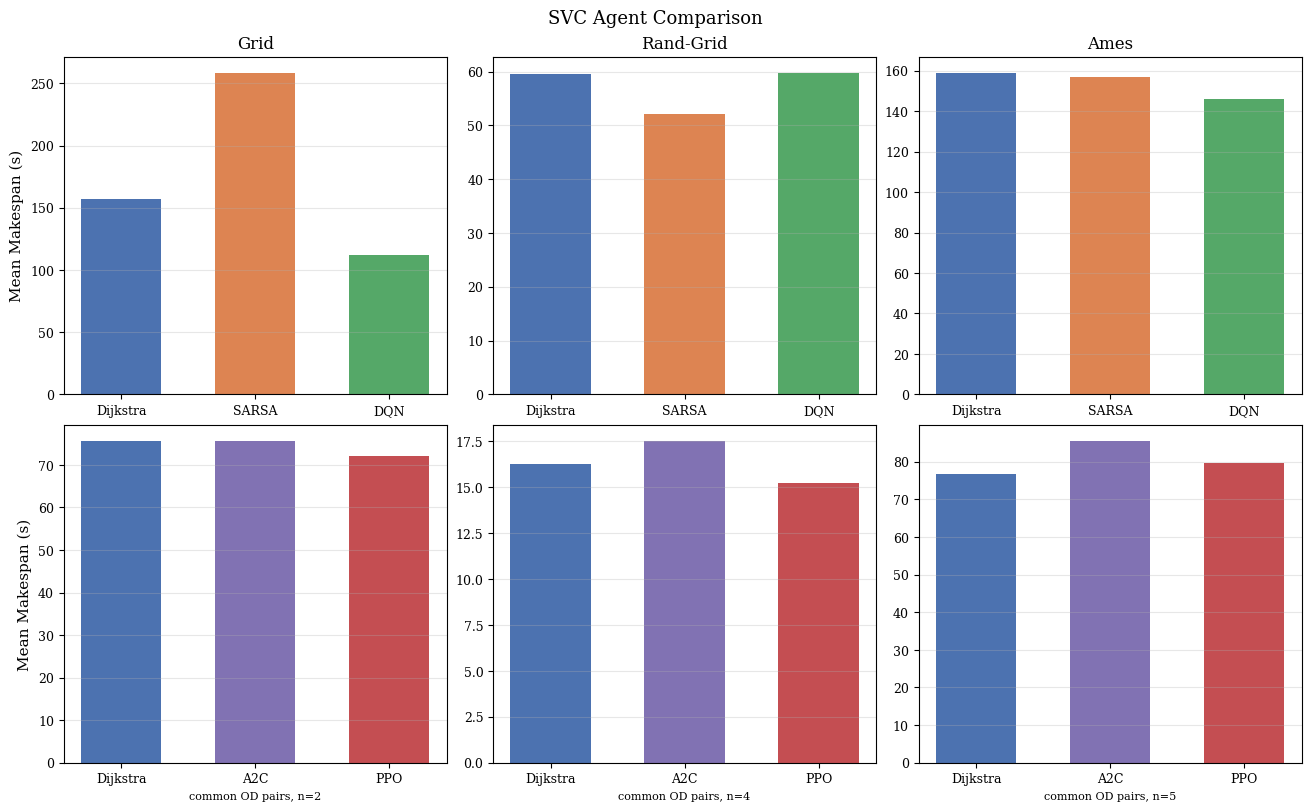

In [6]:
def _svc_dijkstra_csv(net_disp):
    for test_dir in sorted((RUNS / 'dijkstra').glob('test_*'), key=lambda p: int(p.name.split('_')[1])):
        cfg_path = test_dir / 'config.yaml'
        if not cfg_path.exists():
            continue
        cfg = yaml.safe_load(cfg_path.read_text())
        if (cfg.get('net', {}).get('net_path') == NET_PATH[net_disp]
                and cfg.get('traffic', {}).get('model') == 'svc'):
            return test_dir / 'simulation_results.csv'
    raise FileNotFoundError(f'No dijkstra SVC eval for {net_disp}')

def _svc_agent_csv(net_disp, algo):
    row = df_svc[(df_svc['network'] == net_disp) & (df_svc['algo'] == algo)].iloc[0]
    test_dir = sorted((RUNS / row['model']).glob('test_*'))[0]
    return test_dir / 'simulation_results.csv'

SVC_TOP_ALGO_ORDER  = ['SSP', 'SARSA', 'DQN']
SVC_TOP_ALGO_LABELS = ['Dijkstra', 'SARSA', 'DQN']
SVC_TOP_ALGO_COLORS = [SVC_ALGO_COLORS[SVC_ALGO_ORDER.index(a)] for a in SVC_TOP_ALGO_ORDER]

SVC_BOTTOM_ALGO_ORDER  = ['Dijkstra', 'A2C', 'PPO']
SVC_BOTTOM_ALGO_COLORS = [SVC_ALGO_COLORS[SVC_ALGO_ORDER.index(a)] for a in ['SSP', 'A2C', 'PPO']]

# top row: each agent's own successful-OD mean makespan, straight from df_svc (no filtering)
svc_top = df_svc.set_index(['network', 'agent'])['makespan_mean']

# bottom row: per network, intersect the OD pairs Dijkstra/A2C/PPO all solved
# successfully, then average each agent's makespan over that common subset
svc_bottom_rows, svc_bottom_ncommon = [], {}
for net_disp in NET_ORDER:
    times = {
        'Dijkstra': _od_times(_svc_dijkstra_csv(net_disp)),
        'A2C':      _od_times(_svc_agent_csv(net_disp, 'a2c_svc')),
        'PPO':      _od_times(_svc_agent_csv(net_disp, 'ppo_svc')),
    }
    common = list(set(times['Dijkstra'].index) & set(times['A2C'].index) & set(times['PPO'].index))
    svc_bottom_ncommon[net_disp] = len(common)
    for a in SVC_BOTTOM_ALGO_ORDER:
        svc_bottom_rows.append({'network': net_disp, 'agent': a, 'makespan_mean': times[a].loc[common].mean()})
svc_bottom = pd.DataFrame(svc_bottom_rows).set_index(['network', 'agent'])['makespan_mean']

# --- plot ---
x     = np.arange(3)
width = 0.6

fig, axes = plt.subplots(2, 3, figsize=(13, 8), constrained_layout=True)
fig.suptitle('SVC Agent Comparison', fontsize=13)

for col, net in enumerate(NET_ORDER):
    ax = axes[0, col]
    vals = [svc_top.get((net, a), np.nan) for a in SVC_TOP_ALGO_ORDER]
    ax.bar(x, vals, width, color=SVC_TOP_ALGO_COLORS)
    ax.set_title(net, fontsize=12)
    ax.set_xticks(x); ax.set_xticklabels(SVC_TOP_ALGO_LABELS)
    if col == 0: ax.set_ylabel('Mean Makespan (s)')
    ax.grid(True, axis='y', alpha=0.3)

    ax = axes[1, col]
    vals = [svc_bottom.get((net, a), np.nan) for a in SVC_BOTTOM_ALGO_ORDER]
    ax.bar(x, vals, width, color=SVC_BOTTOM_ALGO_COLORS)
    ax.set_xticks(x); ax.set_xticklabels(SVC_BOTTOM_ALGO_ORDER)
    ax.set_xlabel(f'common OD pairs, n={svc_bottom_ncommon[net]}', fontsize=8)
    if col == 0: ax.set_ylabel('Mean Makespan (s)')
    ax.grid(True, axis='y', alpha=0.3)

out = FIG_DIR / 'svc_agent_comparison.png'
fig.savefig(out, bbox_inches='tight', dpi=150)
print('Saved:', out)
plt.show()

## Figure 4 — Ped Agent Comparison (Dijkstra vs DQN, common successful OD pairs)

Saved: /home/shinobi-owl/PhD/battery/DroneSim/results/figures/ped_agent_comparison.png


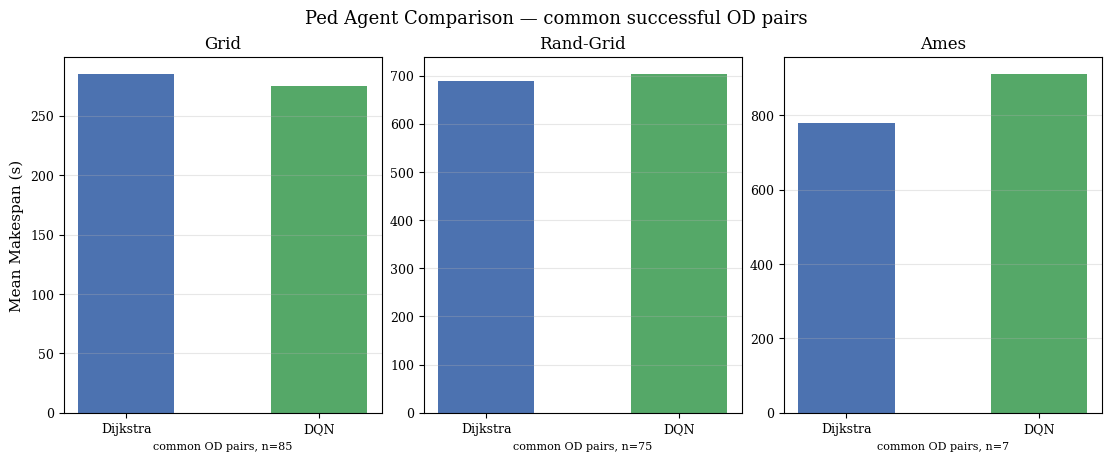

In [7]:
PED_POLICY = {'Grid': '962999ce', 'Rand-Grid': '032c3ac1', 'Ames': '25d8a01c'}

def _latest_test_dir(policy_id):
    tests = sorted((RUNS / policy_id).glob('test_*'), key=lambda p: int(p.name.split('_')[1]))
    return tests[-1]

PED_ALGO_ORDER  = ['Dijkstra', 'DQN']
PED_ALGO_COLORS = [PSL_ALGO_COLORS[PSL_ALGO_ORDER.index(a)] for a in ['SSP', 'DQN']]

# per network: Dijkstra and DQN baselines are co-located in the same eval session
# (same 100 OD pairs), so intersect the OD pairs both solved successfully, then
# average each agent's makespan over that common subset
ped_rows, ped_ncommon = [], {}
for net_disp in NET_ORDER:
    test_dir = _latest_test_dir(PED_POLICY[net_disp])
    times = {
        'Dijkstra': _od_times(test_dir / 'simulation_results_dijkstra.csv'),
        'DQN':      _od_times(test_dir / 'simulation_results.csv'),
    }
    common = list(set(times['Dijkstra'].index) & set(times['DQN'].index))
    ped_ncommon[net_disp] = len(common)
    for a in PED_ALGO_ORDER:
        ped_rows.append({'network': net_disp, 'agent': a, 'makespan_mean': times[a].loc[common].mean()})
ped_avg = pd.DataFrame(ped_rows).set_index(['network', 'agent'])['makespan_mean']

# --- plot ---
x     = np.arange(len(PED_ALGO_ORDER))
width = 0.5

fig, axes = plt.subplots(1, 3, figsize=(11, 4.5), constrained_layout=True)
fig.suptitle('Ped Agent Comparison — common successful OD pairs', fontsize=13)

for col, net in enumerate(NET_ORDER):
    ax = axes[col]
    vals = [ped_avg.get((net, a), np.nan) for a in PED_ALGO_ORDER]
    ax.bar(x, vals, width, color=PED_ALGO_COLORS)
    ax.set_title(net, fontsize=12)
    ax.set_xticks(x); ax.set_xticklabels(PED_ALGO_ORDER)
    ax.set_xlabel(f'common OD pairs, n={ped_ncommon[net]}', fontsize=8)
    if col == 0: ax.set_ylabel('Mean Makespan (s)')
    ax.grid(True, axis='y', alpha=0.3)

out = FIG_DIR / 'ped_agent_comparison.png'
fig.savefig(out, bbox_inches='tight', dpi=150)
print('Saved:', out)
plt.show()

---
## Figure 5 — Highlight Routes: Best DQN Wins over Dijkstra

For each traffic model (PSL, SVC) × network, find the single OD pair where DQN
beats Dijkstra by the largest margin among the OD pairs both solved successfully,
and draw both paths on the road network. Solid lines are the actual edge
sequences from `path_edges`. PSL pools candidates across `K = 1`–`4` and reports
whichever `K` produced the largest win.

Saved: /home/shinobi-owl/PhD/battery/DroneSim/results/figures/highlight_routes_dqn_vs_dijkstra.png


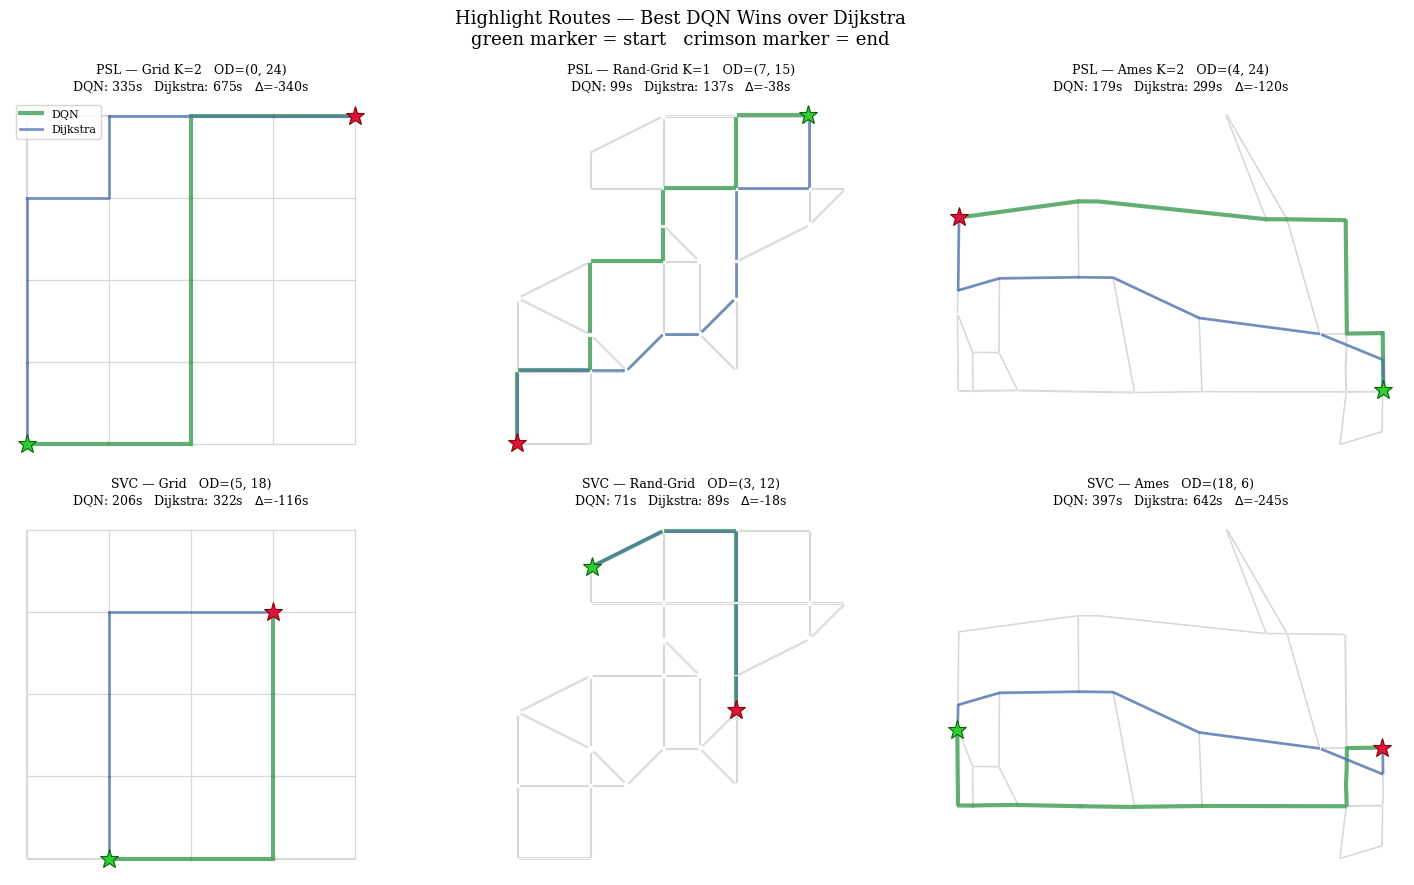

In [8]:
import sumolib

def _od_full(csv_path):
    """(start_idx, target_idx) -> total_time_taken, path_edges for successful runs (see _is_success)."""
    df = pd.read_csv(csv_path)
    df['start_idx']        = pd.to_numeric(df['start_idx'], errors='coerce')
    df['target_idx']       = pd.to_numeric(df['target_idx'], errors='coerce')
    df['total_time_taken'] = pd.to_numeric(df['total_time_taken'], errors='coerce')
    d = df[_is_success(df)].drop_duplicates(subset=['start_idx', 'target_idx'], keep=False)
    return d.set_index(['start_idx', 'target_idx'])[['total_time_taken', 'path_edges']]

def _best_psl_win(net_disp):
    """Best DQN-over-Dijkstra win pooled across K=1-4: (diff, od, dqn_t, dij_t, dqn_edges, dij_edges, K)."""
    net_code = NET_CODE[net_disp]
    best = None
    for K in (1, 2, 3, 4):
        dqn = _od_full(_agent_csv(net_code, K, 'dqn'))
        dij = _od_full(_dijkstra_csv(net_disp, K))
        for key in set(dqn.index) & set(dij.index):
            diff = dqn.loc[key, 'total_time_taken'] - dij.loc[key, 'total_time_taken']
            if best is None or diff < best[0]:
                best = (diff, key, dqn.loc[key, 'total_time_taken'], dij.loc[key, 'total_time_taken'],
                        dqn.loc[key, 'path_edges'], dij.loc[key, 'path_edges'], K)
    return best

def _best_svc_win(net_disp):
    """Best DQN-over-Dijkstra win: (diff, od, dqn_t, dij_t, dqn_edges, dij_edges, K=None)."""
    dqn = _od_full(_svc_agent_csv(net_disp, 'dqn_svc'))
    dij = _od_full(_svc_dijkstra_csv(net_disp))
    best = None
    for key in set(dqn.index) & set(dij.index):
        diff = dqn.loc[key, 'total_time_taken'] - dij.loc[key, 'total_time_taken']
        if best is None or diff < best[0]:
            best = (diff, key, dqn.loc[key, 'total_time_taken'], dij.loc[key, 'total_time_taken'],
                    dqn.loc[key, 'path_edges'], dij.loc[key, 'path_edges'], None)
    return best

_geom_cache = {}
def _net_geom(net_disp):
    """edge_shape[eid] -> [(x,y), ...] shape points, for drawing routes on the road network."""
    if net_disp not in _geom_cache:
        net_xml = NET_PATH[net_disp].replace('.sumocfg', '.net.xml')
        net = sumolib.net.readNet(str(BASE / net_xml), withPedestrianConnections=False)
        edge_shape = {}
        for e in net.getEdges():
            eid = e.getID()
            if eid.startswith(':'):
                continue
            shp = e.getShape()
            if shp:
                edge_shape[eid] = shp
        _geom_cache[net_disp] = edge_shape
    return _geom_cache[net_disp]

def _draw_bg(ax, edge_shape):
    for shp in edge_shape.values():
        ax.plot([p[0] for p in shp], [p[1] for p in shp], color='#d8d8d8', lw=0.8, zorder=1)

def _draw_route(ax, edge_shape, path_str, color, lw, alpha, zorder, label):
    edges = [e.strip() for e in str(path_str).split(';') if e.strip() in edge_shape]
    for i, eid in enumerate(edges):
        shp = edge_shape[eid]
        ax.plot([p[0] for p in shp], [p[1] for p in shp], color=color, lw=lw, alpha=alpha,
                 zorder=zorder, label=label if i == 0 else None)
    return edges

def _mark_ends(ax, edge_shape, edges):
    if edges and edges[0] in edge_shape:
        s = edge_shape[edges[0]][0]
        ax.plot(s[0], s[1], '*', color='limegreen', ms=14, zorder=7, markeredgecolor='darkgreen', mew=0.8)
    if edges and edges[-1] in edge_shape:
        e = edge_shape[edges[-1]][-1]
        ax.plot(e[0], e[1], '*', color='crimson', ms=14, zorder=7, markeredgecolor='darkred', mew=0.8)

DIJ_COLOR = PSL_ALGO_COLORS[PSL_ALGO_ORDER.index('SSP')]
DQN_COLOR = PSL_ALGO_COLORS[PSL_ALGO_ORDER.index('DQN')]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
fig.suptitle('Highlight Routes — Best DQN Wins over Dijkstra\n'
             'green marker = start   crimson marker = end', fontsize=13)

for col, net_disp in enumerate(NET_ORDER):
    edge_shape = _net_geom(net_disp)
    for row, (traffic_label, finder) in enumerate([('PSL', _best_psl_win), ('SVC', _best_svc_win)]):
        ax = axes[row, col]
        diff, od, dqn_t, dij_t, dqn_edges, dij_edges, K = finder(net_disp)

        _draw_bg(ax, edge_shape)
        e_dqn = _draw_route(ax, edge_shape, dqn_edges, DQN_COLOR, lw=3.0, alpha=0.9, zorder=4, label='DQN')
        _draw_route(ax, edge_shape, dij_edges, DIJ_COLOR, lw=2.0, alpha=0.75, zorder=5, label='Dijkstra')
        _mark_ends(ax, edge_shape, e_dqn)

        k_txt = f' K={K}' if K is not None else ''
        ax.set_title(f'{traffic_label} — {net_disp}{k_txt}   OD={od}\n'
                      f'DQN: {dqn_t:.0f}s   Dijkstra: {dij_t:.0f}s   $\\Delta$={diff:+.0f}s', fontsize=9)
        ax.set_aspect('equal')
        ax.axis('off')
        if row == 0 and col == 0:
            ax.legend(fontsize=8, loc='upper left', framealpha=0.8)

plt.tight_layout()
out = FIG_DIR / 'highlight_routes_dqn_vs_dijkstra.png'
fig.savefig(out, bbox_inches='tight', dpi=150)
print('Saved:', out)
plt.show()